# Rational Family Audit
## tl;dr
Este notebook muestra las comparaciones exactas ejecutadas con Gambit racional y el baseline poliédrico. La comparación es entre productos de envolventes convexas compatibles; no se convexifica la unión completa de equilibrios.

## Context & Methods
Gambit16.4.1 lee el NFG real y enumera extremos racionales. El código nuevo proyecta marginales por tipo, construye el grafo de compatibilidad usando payoffs directos y enumera bicliques máximos.
### Key Assumptions
Dos prestamistas y dos tipos; señales condicionalmente independientes; prior interior; payoff a_i(theta+alpha*a_j-c). La reconstrucción depende de la enumeración externa completa. Sin inferencia causal ni datos observados; S2 parcial.

In [1]:
import csv,json
from pathlib import Path
print(json.loads(Path('results/config.json').read_text()))
print(json.loads(Path('results/metadata.json').read_text()))

{'regular': {'prior': 0.5, 'accuracy': 0.8, 'cost': 0.9, 'complementarity': 0.8}, 'coordination_family': {'prior': 0.5, 'accuracy': 0.5, 'cost': 0.9, 'complementarity': 0.8}, 'full_indifference': {'prior': 0.5, 'accuracy': 0.5, 'cost': 0.5, 'complementarity': 0}, 'singular_isolated': {'prior': 0.5, 'accuracy': 1, 'cost': 1, 'complementarity': 0.8}, 'near_family': {'prior': 0.5, 'accuracy': 0.500000001, 'cost': 0.9, 'complementarity': 0.8}, 'random_0': {'prior': 0.4, 'accuracy': 0.5, 'cost': 0.8, 'complementarity': 0.8}, 'random_1': {'prior': 0.3, 'accuracy': 1.0, 'cost': 0.2, 'complementarity': 0.8}, 'random_2': {'prior': 0.5, 'accuracy': 0.9, 'cost': 0.9, 'complementarity': 0.8}, 'random_3': {'prior': 0.6, 'accuracy': 0.9, 'cost': 0.9, 'complementarity': 0.8}, 'random_4': {'prior': 0.8, 'accuracy': 0.7, 'cost': 1.0, 'complementarity': 0.8}, 'random_5': {'prior': 0.3, 'accuracy': 0.8, 'cost': 0.9, 'complementarity': 0.8}, 'random_6': {'prior': 0.5, 'accuracy': 0.9, 'cost': 1.0, 'comple

## Data
Matrices sintéticas racionales .nfg; el parser externo verifica las32 entradas. Perfiles crudos y familias exactas están en profiles.csv y families.json. Seed20261017.

In [2]:
print(Path('results/regular.nfg').read_text())
for row in list(csv.DictReader(Path('results/summary.csv').open()))[:5]:
    print({k:row[k] for k in ['scenario','gambit_profiles','baseline_families','reconstructed_families','dimensions','exact_equal','max_interim_regret']})

NFG 1 R "Bayesian credit freeze" { "Lender 0" "Lender 1" } { 4 4 }

0 0 -1/20 0 -7/20 0 -2/5 0 0 -1/20 111/500 111/500 -111/500 39/500 0 7/20 0 -7/20 39/500 -111/500 -39/500 -39/500 0 1/20 0 -2/5 7/20 0 1/20 0 2/5 2/5

{'scenario': 'regular', 'gambit_profiles': '5', 'baseline_families': '5', 'reconstructed_families': '5', 'dimensions': '[0, 0, 0, 0, 0]', 'exact_equal': 'True', 'max_interim_regret': '0'}
{'scenario': 'coordination_family', 'gambit_profiles': '11', 'baseline_families': '3', 'reconstructed_families': '3', 'dimensions': '[0, 2, 0]', 'exact_equal': 'True', 'max_interim_regret': '0'}
{'scenario': 'full_indifference', 'gambit_profiles': '16', 'baseline_families': '1', 'reconstructed_families': '1', 'dimensions': '[4]', 'exact_equal': 'True', 'max_interim_regret': '0'}
{'scenario': 'singular_isolated', 'gambit_profiles': '2', 'baseline_families': '2', 'reconstructed_families': '2', 'dimensions': '[0, 0]', 'exact_equal': 'True', 'max_interim_regret': '0'}
{'scenario': 'near_fam

## Results
Figura editable desde benchmarks/run.py, generada a partir de resultados ejecutados. Las barras derechas son controles negativos, no estimaciones empíricas.

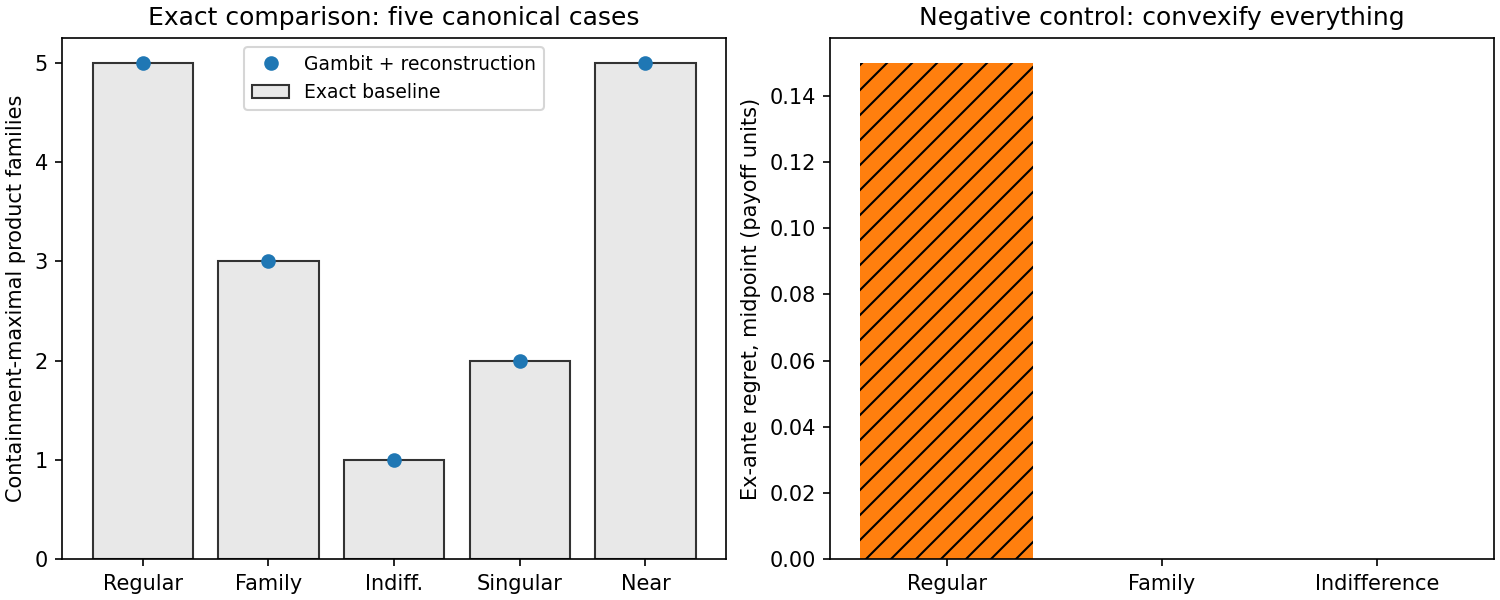

In [3]:
from IPython.display import Image,display
display(Image(filename='results/comparison.png'))

In [4]:
print(Path('results/ablations.csv').read_text())
print(Path('results/coverage.txt').read_text())

scenario,ablation,candidate,exact_exante_regret,true_max_dimension,first_profile_only_dimension,profiles
regular,convexify_all_equilibria,"[1/2,1/2,1/2,1/2]",3/20,0,0,5
coordination_family,convexify_all_equilibria,"[1/2,1/2,1/2,1/2]",0,2,0,11
full_indifference,convexify_all_equilibria,"[1/2,1/2,1/2,1/2]",0,4,0,16

Name              Stmts   Miss Branch BrPart  Cover   Missing
-------------------------------------------------------------
src/families.py      86      0     32      0   100%
-------------------------------------------------------------
TOTAL                86      0     32      0   100%



## Takeaways
La igualdad exacta de familias en los casos ejecutados amplía la evidencia S2, no demuestra un teorema de completitud general ni S3 del programa. Un punto o una envolvente global pierden la estructura de multiplicidad; ver informe.md para casos negativos, coste y límites.

## Desarrollo experimental ampliado — 18 de octubre de 2026

Las siguientes celdas recalculan nuevos experimentos desde los modelos e inputs. Los resultados históricos anteriores se conservan como evidencia separada. Cada experimento declara su alcance; no eleva automáticamente la madurez del proyecto.

### 1. Por qué una unión de equilibrios no es convexa
En el juego simétrico de coordinación con pago $u_i=a_i(a_j-c)$ y $c=3/4$, hay equilibrios puros en (0,0), (1,1) y uno mixto en (c,c). El punto medio entre los puros no es equilibrio: jugar con probabilidad 1/2 genera una pérdida evitable de 1/8. Por tanto, convexificar todos los perfiles crea soluciones espurias. Esta sección deriva el contraejemplo directamente, sin depender del enumerador externo.

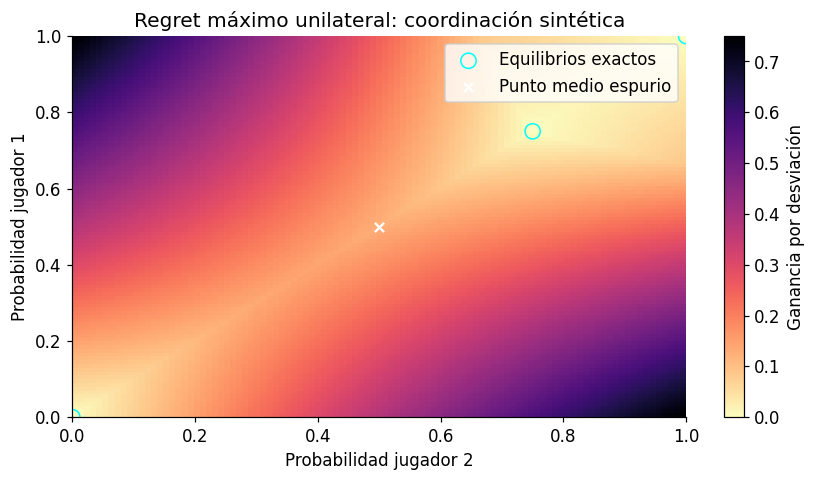

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
from fractions import Fraction as F
c=F(3,4)
def coordination_regret(x,y,cost):
    gx,gy=y-cost,x-cost
    return max(F(0),max(F(0),gx)-x*gx,max(F(0),gy)-y*gy)
assert coordination_regret(F(0),F(0),c)==0
assert coordination_regret(F(1),F(1),c)==0
assert coordination_regret(c,c,c)==0
assert coordination_regret(F(1,2),F(1,2),c)==F(1,8)
grid=np.linspace(0,1,101)
regret_grid=np.array([[float(coordination_regret(F(str(x)),F(str(y)),c)) for y in grid] for x in grid])
fig,ax=plt.subplots()
im=ax.imshow(regret_grid,origin='lower',extent=[0,1,0,1],aspect='auto',cmap='magma_r')
ax.scatter([0,.75,1],[0,.75,1],facecolors='none',edgecolors='cyan',s=100,label='Equilibrios exactos')
ax.scatter([.5],[.5],marker='x',color='white',label='Punto medio espurio')
ax.set(xlabel='Probabilidad jugador 2',ylabel='Probabilidad jugador 1',title='Regret máximo unilateral: coordinación sintética')
ax.legend();fig.colorbar(im,ax=ax,label='Ganancia por desviación');plt.show()

### 2. Proyección por tipo: información conservada y perdida
Una mezcla sobre políticas (00,01,10,11) se proyecta en dos marginales. Las mezclas (1/2,0,0,1/2) y (0,1/2,1/2,0) tienen idénticas marginales y correlación contrafactual opuesta. Sólo un tipo se realiza para cada jugador. Bajo independencia de las mezclas entre jugadores, las utilidades dependen de esas marginales, no del acoplamiento entre acciones contrafactuales de un mismo jugador.

In [6]:
policies=np.array([[0,0],[0,1],[1,0],[1,1]])
p_mix=np.array([.5,0,0,.5]);q_mix=np.array([0,.5,.5,0])
assert np.allclose(p_mix@policies,q_mix@policies)
display(pd.DataFrame({'política':['00','01','10','11'],'mezcla A':p_mix,'mezcla B':q_mix}))
print('Marginales comunes:',p_mix@policies)
print('Probabilidad conjunta contrafactual de dos unos:',p_mix[3],q_mix[3])
records=list(csv.DictReader(Path('results/summary.csv').open()))
audit_table=pd.DataFrame([dict(scenario=row['scenario'],external_profiles=int(row['gambit_profiles']),
    families=int(row['reconstructed_families']),max_dimension=max(json.loads(row['dimensions'])),
    exact_equal=row['exact_equal']=='True') for row in records])
display(audit_table)
assert audit_table.exact_equal.all()

Marginales comunes: [0.5 0.5]
Probabilidad conjunta contrafactual de dos unos: 0.5 0.0


,política,mezcla A,mezcla B
0,00,0.5,0.0
1,01,0.0,0.5
2,10,0.0,0.5
3,11,0.5,0.0


,scenario,external_profiles,families,max_dimension,exact_equal
0,regular,5,5,0,True
1,coordination_family,11,3,2,True
2,full_indifference,16,1,4,True
3,singular_isolated,2,2,0,True
4,near_family,5,5,0,True
5,random_0,11,3,2,True
6,random_1,3,3,0,True
7,random_2,3,3,0,True
8,random_3,3,3,0,True
9,random_4,3,3,0,True


### 3. Lectura de la evidencia externa
El conteo de perfiles externos y el de familias responden preguntas distintas: los extremos representan geometría y las familias describen conjuntos de equilibrios. La igualdad exacta registrada es evidencia de los escenarios del corpus, no una prueba de completitud universal. Aquí se releen resultados externos existentes; no se afirma haber vuelto a ejecutar Gambit.

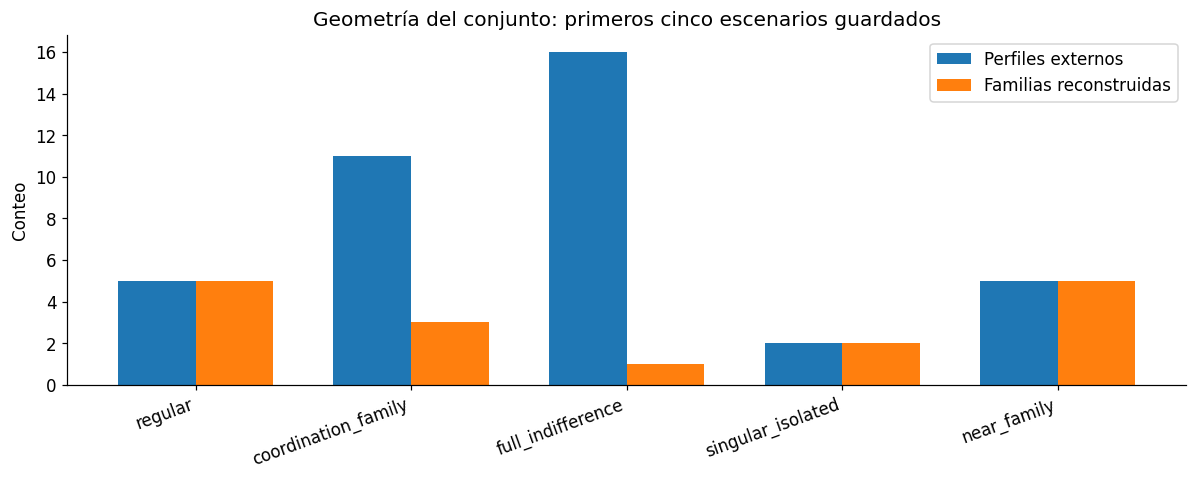

In [7]:
fig,ax=plt.subplots(figsize=(11,4.5))
selected=audit_table.head(5)
positions=np.arange(len(selected))
ax.bar(positions-.18,selected.external_profiles,.36,label='Perfiles externos')
ax.bar(positions+.18,selected.families,.36,label='Familias reconstruidas')
ax.set_xticks(positions,selected.scenario,rotation=20,ha='right')
ax.set(ylabel='Conteo',title='Geometría del conjunto: primeros cinco escenarios guardados')
ax.legend();fig.tight_layout();plt.show()

### 4. Condiciones de extensión
El mapa de regret se recalcula con fracciones exactas en una subclase de coordinación; no reemplaza el juego bayesiano completo. La reconstrucción por compatibilidad requiere extremos completos, y su búsqueda exponencial está acotada. Extender a más tipos exige revisar tanto el costo combinatorio como las condiciones que permiten representar familias mediante productos de envolventes.

### Lectura de los resultados ejecutados

El punto medio de los equilibrios puros tiene regret exacto **1/8**, frente a cero en los tres equilibrios del contraejemplo. Las dos mezclas de políticas conservan marginales **(0.5, 0.5)**, mientras la masa conjunta contrafactual en (1,1) cambia de **0.5 a 0**. Son dos operaciones distintas: preservar marginales no autoriza convexificar la unión de equilibrios.